In [2]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PATH = "/content/drive/MyDrive/fraud-detection"
df = pd.read_csv(f"{PATH}/data/paysim.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
print(df.shape)
df.info()
print(df.isnull().sum())
df.describe()

(6362620, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64


,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


isFraud
0    6354407
1       8213
Name: count, dtype: int64
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


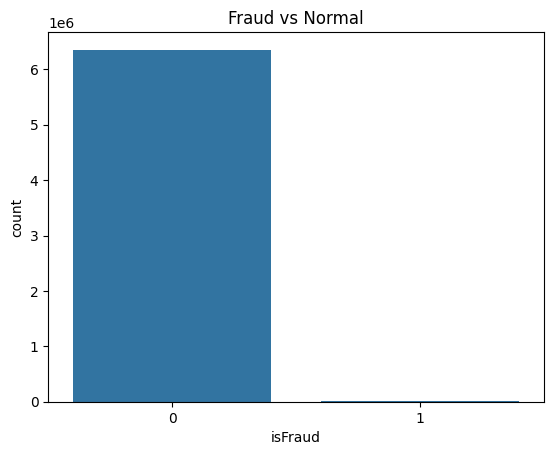

In [5]:
print(df["isFraud"].value_counts())
print(df["isFraud"].value_counts(normalize=True) * 100)

sns.countplot(x="isFraud", data=df)
plt.title("Fraud vs Normal")
plt.savefig(f"{PATH}/figures/01_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
print(pd.crosstab(df["type"], df["isFraud"]))

isFraud         0     1
type                   
CASH_IN   1399284     0
CASH_OUT  2233384  4116
DEBIT       41432     0
PAYMENT   2151495     0
TRANSFER   528812  4097


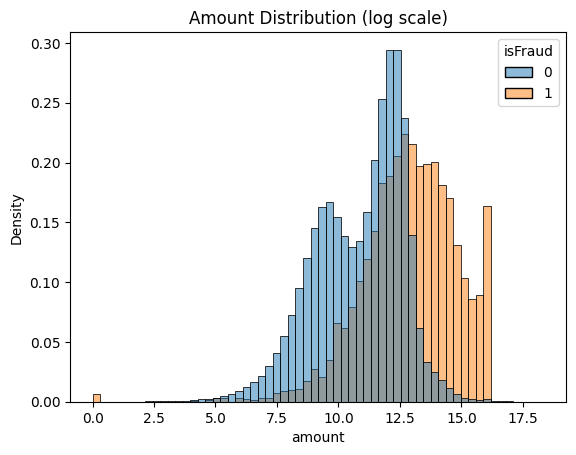

In [9]:
sns.histplot(x=np.log1p(df["amount"]), hue=df["isFraud"],
             stat="density", common_norm=False, bins=60)
plt.title("Amount Distribution (log scale)")
plt.savefig(f"{PATH}/figures/02_amount_dist.png", dpi=150, bbox_inches="tight")
plt.show()

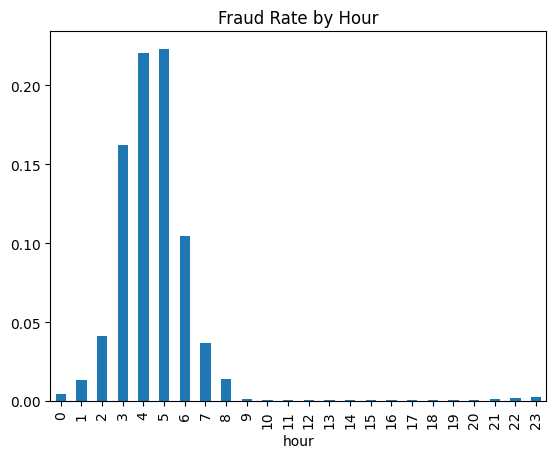

In [10]:
df["hour"] = df["step"] % 24
df.groupby("hour")["isFraud"].mean().plot(kind="bar")
plt.title("Fraud Rate by Hour")
plt.savefig(f"{PATH}/figures/03_fraud_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
fraud = df[df["isFraud"] == 1]
print("نسبة الاحتيال اللي فضّت الحساب:", (fraud["newbalanceOrig"] == 0).mean())

نسبة الاحتيال اللي فضّت الحساب: 0.9805186898818946


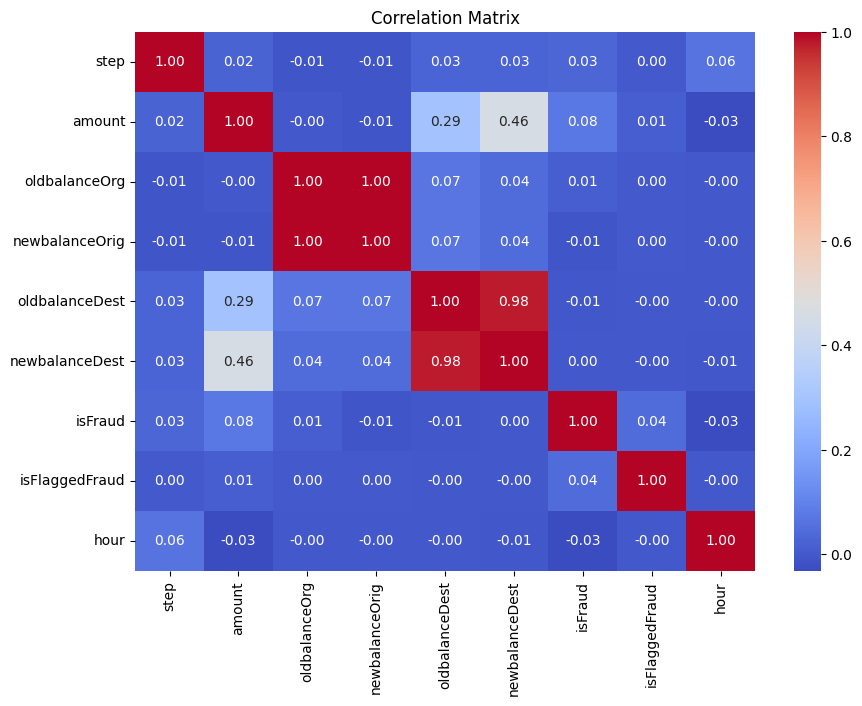

In [13]:
num = df.select_dtypes("number")
plt.figure(figsize=(10, 7))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.savefig(f"{PATH}/figures/04_correlation.png", dpi=150, bbox_inches="tight")
plt.show()